In [1]:
import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
url = "https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue"

print(url)

https://en.wikipedia.org/wiki/List_of_largest_companies_in_the_United_States_by_revenue


In [4]:
headers = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 Chrome/140.0.0.0 Safari/537.36"
}

response = requests.get(url, headers=headers)

print(response.status_code)

200


In [5]:
print(response.text[:1000])

<!DOCTYPE html>
<html class="client-nojs vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vector-feature-main-menu-pinned-disabled vector-feature-limited-width-clientpref-1 vector-feature-limited-width-content-enabled vector-feature-custom-font-size-clientpref-1 vector-feature-appearance-pinned-clientpref-1 skin-theme-clientpref-day vector-sticky-header-enabled vector-toc-available skin-thumbsize-clientpref-standard" lang="en" dir="ltr">
<head>
<meta charset="UTF-8">
<title>List of largest companies in the United States by revenue - Wikipedia</title>
<script>(function(){var className="client-js vector-feature-language-in-header-enabled vector-feature-language-in-main-menu-disabled vector-feature-language-in-main-page-header-disabled vector-feature-page-tools-pinned-disabled vector-feature-toc-pinned-clientpref-1 vec

In [6]:
soup = BeautifulSoup(response.text, "html.parser")

print(soup.title.text)

List of largest companies in the United States by revenue - Wikipedia


In [7]:
tables = soup.find_all("table")

print("Number of tables found:", len(tables))

Number of tables found: 3


In [8]:
for i, table in enumerate(tables):
    print("TABLE", i)
    print(table.get_text(" ", strip=True)[:500])
    print("-" * 80)

TABLE 0
Rank Name Industry Revenue (USD millions) Revenue growth Employees Headquarters 1 Walmart Retail 680,985 5.1% 2,100,000 Bentonville, Arkansas 2 Amazon Retail and cloud computing 637,959 11.0% 1,556,000 Seattle, Washington 3 UnitedHealth Group Healthcare 400,278 7.7% 400,000 Minnetonka, Minnesota 4 Apple Technology 391,035 2.0% 164,000 Cupertino, California 5 CVS Health Healthcare 372,809 4.2% 259,500 Woonsocket, Rhode Island 6 Berkshire Hathaway Conglomerate 371,433 1.9% 392,400 Omaha, Nebraska 
--------------------------------------------------------------------------------
TABLE 1
Rank Name Industry Revenue (USD billions) Employees Headquarters 1 Cargill Food & Drink 154 155,000 Minnetonka, Minnesota 2 Koch Multicompany 125 120,000 Wichita, Kansas 3 Publix Super Markets Food Markets 59.7 260,000 Lakeland, Florida 4 Mars Food & Drink 55 150,000 McLean, Virginia 5 H-E-B Grocery Company Food Markets 49.57 175,000 San Antonio, Texas 6 Reyes Holdings Food, Drink & Tobacco 44 36,00

In [9]:
company_table = None

for table in tables:
    headers = [
        th.get_text(" ", strip=True)
        for th in table.find_all("th")
    ]
    
    if "Rank" in headers and "Name" in headers and "Industry" in headers:
        company_table = table
        print("Company table found!")
        print(headers)
        break

Company table found!
['Rank', 'Name', 'Industry', 'Revenue (USD millions)', 'Revenue growth', 'Employees', 'Headquarters']


In [10]:
headers = [
    th.get_text(" ", strip=True)
    for th in company_table.find_all("th")
]

print(headers)

['Rank', 'Name', 'Industry', 'Revenue (USD millions)', 'Revenue growth', 'Employees', 'Headquarters']


In [11]:
rows = []

for tr in company_table.find_all("tr")[1:]:
    cells = tr.find_all(["td", "th"])
    
    row = [
        cell.get_text(" ", strip=True)
        for cell in cells
    ]
    
    if row:
        rows.append(row)

print("Number of rows scraped:", len(rows))

Number of rows scraped: 100


In [12]:
print(rows[0])

['1', 'Walmart', 'Retail', '680,985', '5.1%', '2,100,000', 'Bentonville, Arkansas']


In [13]:
df = pd.DataFrame(rows, columns=headers)

df.head()

,Rank,Name,Industry,Revenue (USD millions),Revenue growth,Employees,Headquarters
0,1,Walmart,Retail,"680,985",5.1%,"2,100,000","Bentonville, Arkansas"
1,2,Amazon,Retail and cloud computing,"637,959",11.0%,"1,556,000","Seattle, Washington"
2,3,UnitedHealth Group,Healthcare,"400,278",7.7%,"400,000","Minnetonka, Minnesota"
3,4,Apple,Technology,"391,035",2.0%,"164,000","Cupertino, California"
4,5,CVS Health,Healthcare,"372,809",4.2%,"259,500","Woonsocket, Rhode Island"


In [14]:
df.shape

(100, 7)

In [15]:
df.columns

Index(['Rank', 'Name', 'Industry', 'Revenue (USD millions)', 'Revenue growth',
       'Employees', 'Headquarters'],
      dtype='str')

In [17]:
df.columns = [
    col.strip()
    .lower()
    .replace(" ", "_")
    .replace("(", "")
    .replace(")", "")
    for col in df.columns
]

print(df.columns.tolist())

['rank', 'name', 'industry', 'revenue_usd_millions', 'revenue_growth', 'employees', 'headquarters']


In [18]:
df.head()

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters
0,1,Walmart,Retail,"680,985",5.1%,"2,100,000","Bentonville, Arkansas"
1,2,Amazon,Retail and cloud computing,"637,959",11.0%,"1,556,000","Seattle, Washington"
2,3,UnitedHealth Group,Healthcare,"400,278",7.7%,"400,000","Minnetonka, Minnesota"
3,4,Apple,Technology,"391,035",2.0%,"164,000","Cupertino, California"
4,5,CVS Health,Healthcare,"372,809",4.2%,"259,500","Woonsocket, Rhode Island"


In [19]:
top10 = df.head(10).copy()

top10

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters
0,1,Walmart,Retail,"680,985",5.1%,"2,100,000","Bentonville, Arkansas"
1,2,Amazon,Retail and cloud computing,"637,959",11.0%,"1,556,000","Seattle, Washington"
2,3,UnitedHealth Group,Healthcare,"400,278",7.7%,"400,000","Minnetonka, Minnesota"
3,4,Apple,Technology,"391,035",2.0%,"164,000","Cupertino, California"
4,5,CVS Health,Healthcare,"372,809",4.2%,"259,500","Woonsocket, Rhode Island"
5,6,Berkshire Hathaway,Conglomerate,"371,433",1.9%,"392,400","Omaha, Nebraska"
6,7,Alphabet,Technology and cloud computing,"350,018",13.9%,"183,323","Mountain View, California"
7,8,Exxon Mobil,Petroleum,"349,595",1.5%,"60,900","Spring, Texas"
8,9,McKesson Corporation,Healthcare,"308,951",11.7%,"48,000","Irving, Texas"
9,10,Cencora,Pharmacy wholesale,"293,959",12.1%,"44,000","Conshohocken, Pennsylvania"


In [20]:
top10.reset_index(drop=True, inplace=True)

top10

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters
0,1,Walmart,Retail,"680,985",5.1%,"2,100,000","Bentonville, Arkansas"
1,2,Amazon,Retail and cloud computing,"637,959",11.0%,"1,556,000","Seattle, Washington"
2,3,UnitedHealth Group,Healthcare,"400,278",7.7%,"400,000","Minnetonka, Minnesota"
3,4,Apple,Technology,"391,035",2.0%,"164,000","Cupertino, California"
4,5,CVS Health,Healthcare,"372,809",4.2%,"259,500","Woonsocket, Rhode Island"
5,6,Berkshire Hathaway,Conglomerate,"371,433",1.9%,"392,400","Omaha, Nebraska"
6,7,Alphabet,Technology and cloud computing,"350,018",13.9%,"183,323","Mountain View, California"
7,8,Exxon Mobil,Petroleum,"349,595",1.5%,"60,900","Spring, Texas"
8,9,McKesson Corporation,Healthcare,"308,951",11.7%,"48,000","Irving, Texas"
9,10,Cencora,Pharmacy wholesale,"293,959",12.1%,"44,000","Conshohocken, Pennsylvania"


In [21]:
top10.isnull().sum()

rank                    0
name                    0
industry                0
revenue_usd_millions    0
revenue_growth          0
employees               0
headquarters            0
dtype: int64

In [22]:
top10.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   rank                  10 non-null     str  
 1   name                  10 non-null     str  
 2   industry              10 non-null     str  
 3   revenue_usd_millions  10 non-null     str  
 4   revenue_growth        10 non-null     str  
 5   employees             10 non-null     str  
 6   headquarters          10 non-null     str  
dtypes: str(7)
memory usage: 692.0 bytes


In [23]:
top10["revenue_usd_millions"] = (
    top10["revenue_usd_millions"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

top10["revenue_usd_millions"] = pd.to_numeric(
    top10["revenue_usd_millions"],
    errors="coerce"
)

top10["revenue_usd_millions"]

0    680985
1    637959
2    400278
3    391035
4    372809
5    371433
6    350018
7    349595
8    308951
9    293959
Name: revenue_usd_millions, dtype: int64

In [24]:
top10["employees"] = (
    top10["employees"]
    .astype(str)
    .str.replace(",", "", regex=False)
)

top10["employees"] = pd.to_numeric(
    top10["employees"],
    errors="coerce"
)

top10["employees"]

0    2100000
1    1556000
2     400000
3     164000
4     259500
5     392400
6     183323
7      60900
8      48000
9      44000
Name: employees, dtype: int64

In [25]:
top10["revenue_growth"] = (
    top10["revenue_growth"]
    .astype(str)
    .str.replace("%", "", regex=False)
)

top10["revenue_growth"] = pd.to_numeric(
    top10["revenue_growth"],
    errors="coerce"
)

top10["revenue_growth"]

0     5.1
1    11.0
2     7.7
3     2.0
4     4.2
5     1.9
6    13.9
7     1.5
8    11.7
9    12.1
Name: revenue_growth, dtype: float64

In [26]:
top10.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 7 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rank                  10 non-null     str    
 1   name                  10 non-null     str    
 2   industry              10 non-null     str    
 3   revenue_usd_millions  10 non-null     int64  
 4   revenue_growth        10 non-null     float64
 5   employees             10 non-null     int64  
 6   headquarters          10 non-null     str    
dtypes: float64(1), int64(2), str(4)
memory usage: 692.0 bytes


In [27]:
top10

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters
0,1,Walmart,Retail,680985,5.1,2100000,"Bentonville, Arkansas"
1,2,Amazon,Retail and cloud computing,637959,11.0,1556000,"Seattle, Washington"
2,3,UnitedHealth Group,Healthcare,400278,7.7,400000,"Minnetonka, Minnesota"
3,4,Apple,Technology,391035,2.0,164000,"Cupertino, California"
4,5,CVS Health,Healthcare,372809,4.2,259500,"Woonsocket, Rhode Island"
5,6,Berkshire Hathaway,Conglomerate,371433,1.9,392400,"Omaha, Nebraska"
6,7,Alphabet,Technology and cloud computing,350018,13.9,183323,"Mountain View, California"
7,8,Exxon Mobil,Petroleum,349595,1.5,60900,"Spring, Texas"
8,9,McKesson Corporation,Healthcare,308951,11.7,48000,"Irving, Texas"
9,10,Cencora,Pharmacy wholesale,293959,12.1,44000,"Conshohocken, Pennsylvania"


In [28]:
top10.describe()

,revenue_usd_millions,revenue_growth,employees
count,10.000000,10.00000,1.000000e+01
mean,415702.200000,7.11000,5.208123e+05
std,133050.039028,4.77015,7.124646e+05
min,293959.000000,1.50000,4.400000e+04
25%,349700.750000,2.55000,8.667500e+04
50%,372121.000000,6.40000,2.214115e+05
75%,397967.250000,11.52500,3.981000e+05
max,680985.000000,13.90000,2.100000e+06


In [29]:
highest_revenue_company = top10.loc[
    top10["revenue_usd_millions"].idxmax()
]

print("Company with the highest revenue:")
print(highest_revenue_company["name"])
print(
    f"Revenue: ${highest_revenue_company['revenue_usd_millions']:,.0f} million"
)

Company with the highest revenue:
Walmart
Revenue: $680,985 million


In [30]:
fastest_growing_company = top10.loc[
    top10["revenue_growth"].idxmax()
]

print("Company with the highest revenue growth:")
print(fastest_growing_company["name"])
print(
    f"Revenue Growth: {fastest_growing_company['revenue_growth']:.1f}%"
)

Company with the highest revenue growth:
Alphabet
Revenue Growth: 13.9%


In [31]:
largest_employer = top10.loc[
    top10["employees"].idxmax()
]

print("Company with the largest workforce:")
print(largest_employer["name"])
print(
    f"Employees: {largest_employer['employees']:,}"
)

Company with the largest workforce:
Walmart
Employees: 2,100,000


In [32]:
total_revenue = top10["revenue_usd_millions"].sum()

print(f"Total revenue of the Top 10 companies: ${total_revenue:,.0f} million")

Total revenue of the Top 10 companies: $4,157,022 million


In [33]:
average_revenue = top10["revenue_usd_millions"].mean()

print(f"Average revenue: ${average_revenue:,.2f} million")

Average revenue: $415,702.20 million


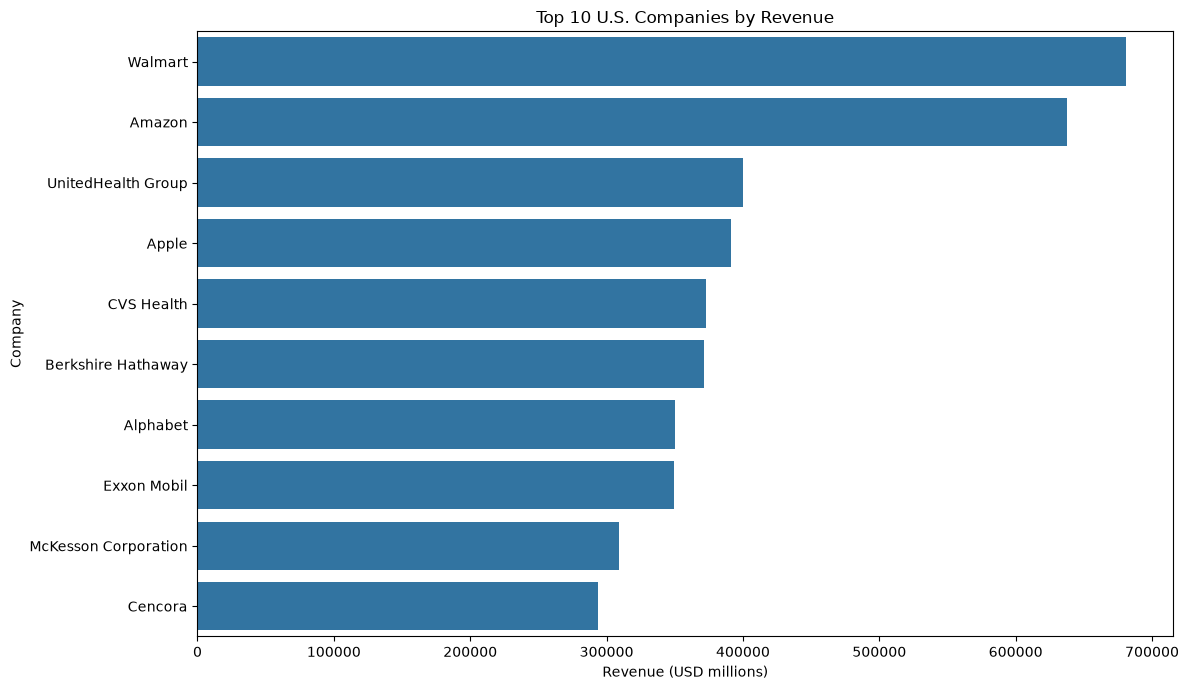

In [34]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x="revenue_usd_millions",
    y="name"
)

plt.title("Top 10 U.S. Companies by Revenue")
plt.xlabel("Revenue (USD millions)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

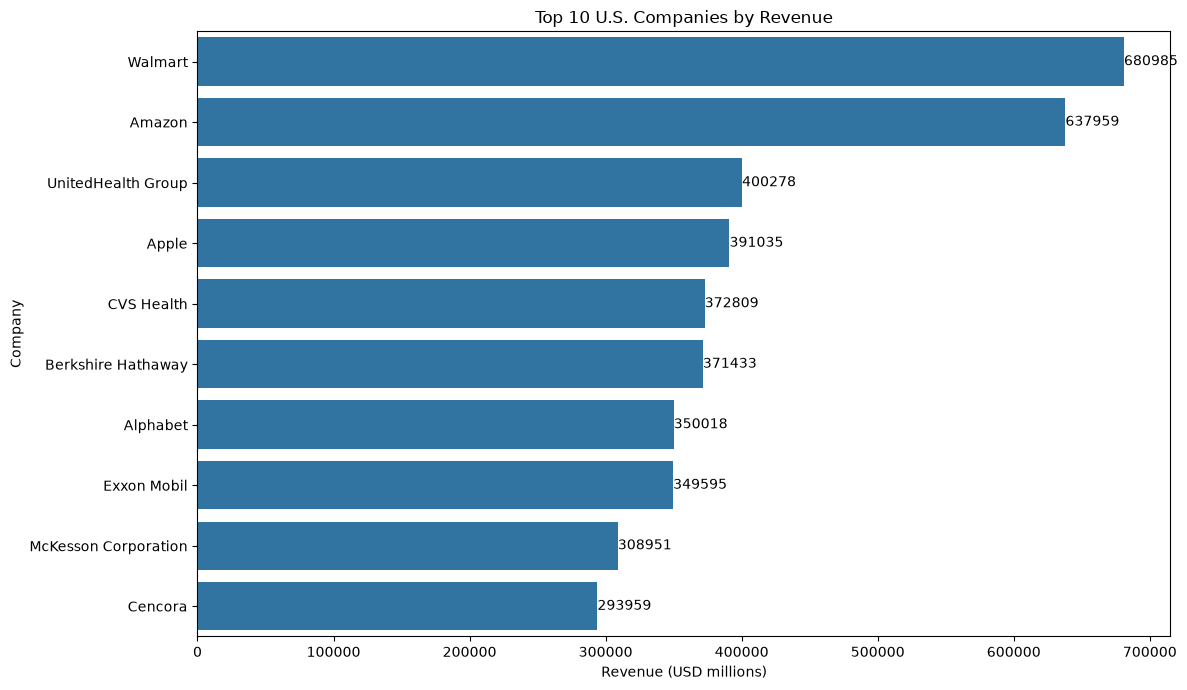

In [35]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top10,
    x="revenue_usd_millions",
    y="name"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Top 10 U.S. Companies by Revenue")
plt.xlabel("Revenue (USD millions)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

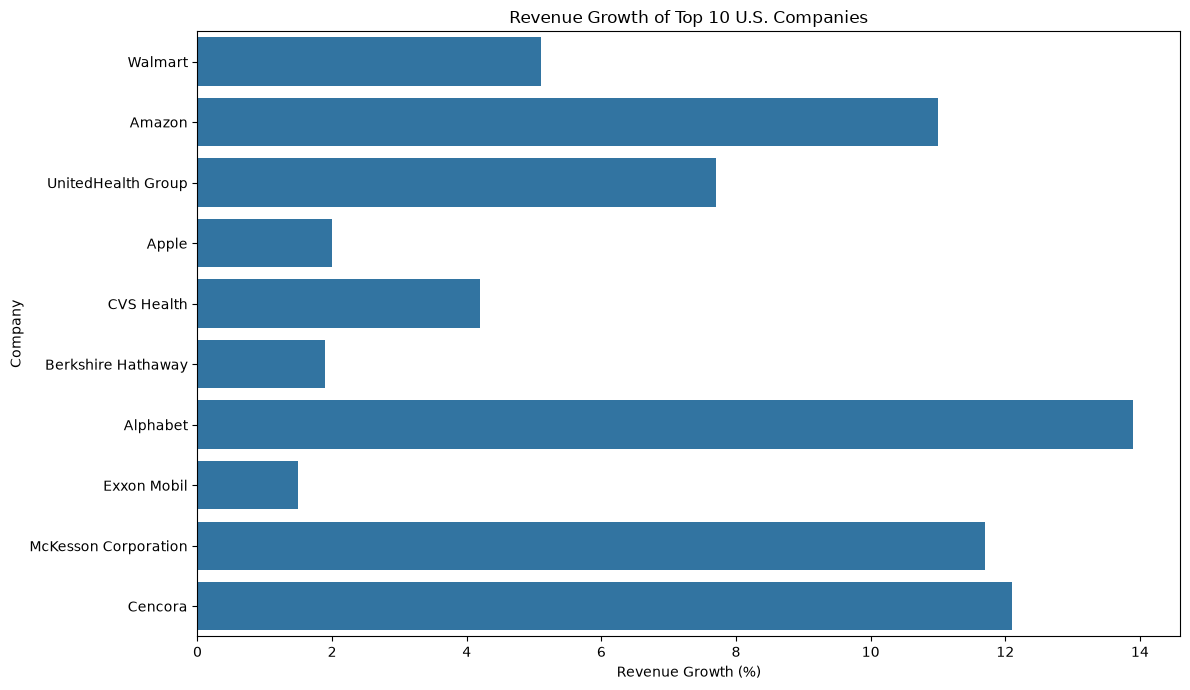

In [36]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x="revenue_growth",
    y="name"
)

plt.title("Revenue Growth of Top 10 U.S. Companies")
plt.xlabel("Revenue Growth (%)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

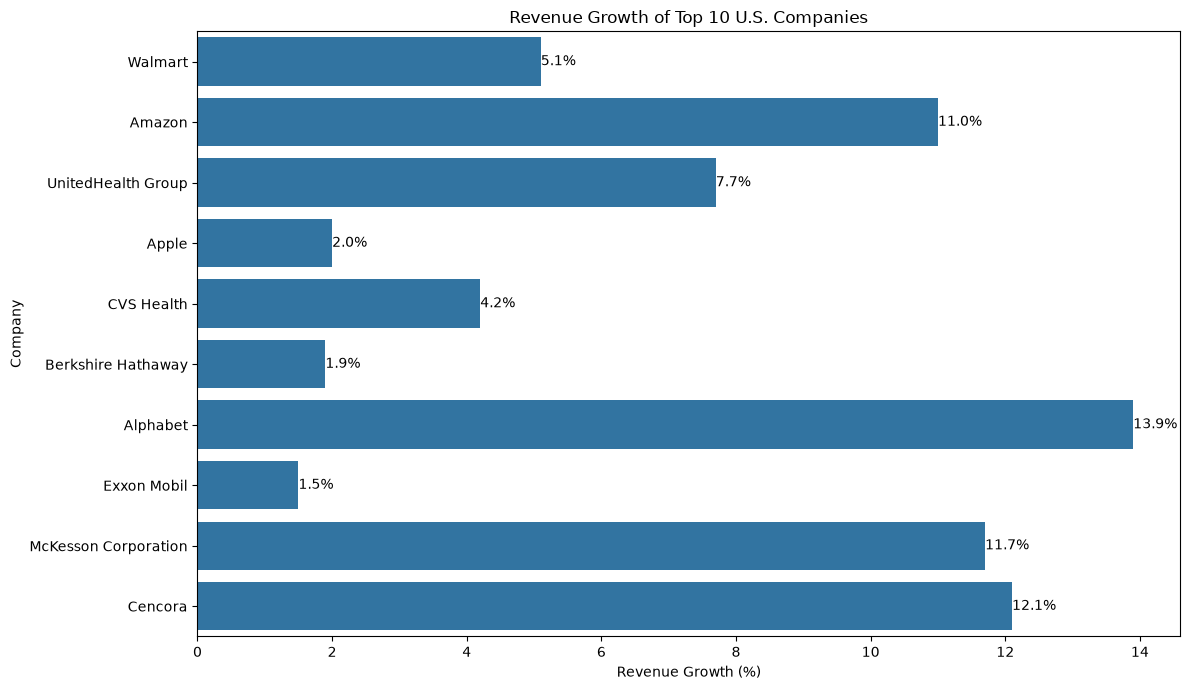

In [37]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top10,
    x="revenue_growth",
    y="name"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%")

plt.title("Revenue Growth of Top 10 U.S. Companies")
plt.xlabel("Revenue Growth (%)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

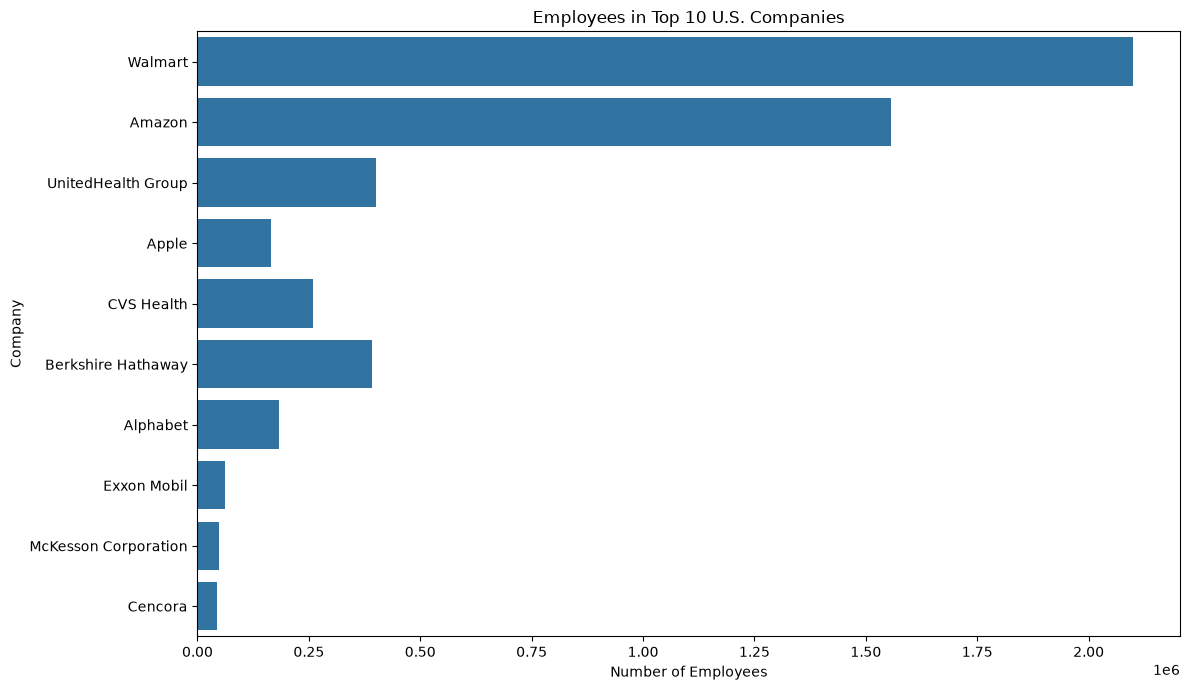

In [38]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top10,
    x="employees",
    y="name"
)

plt.title("Employees in Top 10 U.S. Companies")
plt.xlabel("Number of Employees")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

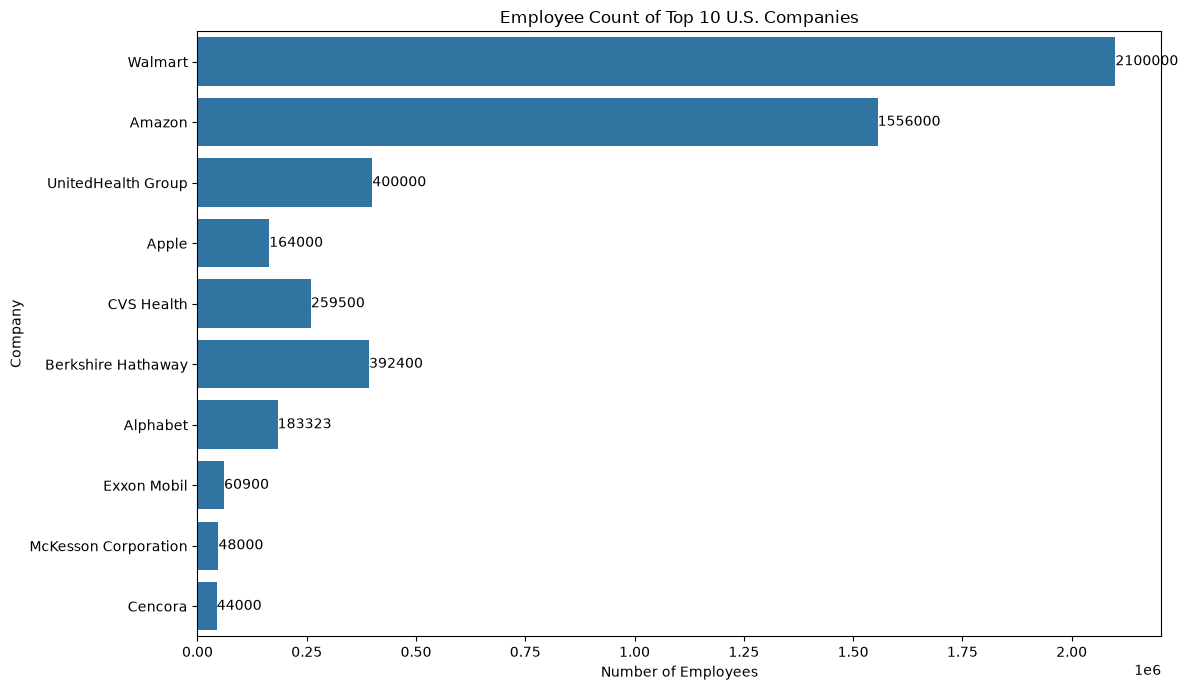

In [39]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=top10,
    x="employees",
    y="name"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Employee Count of Top 10 U.S. Companies")
plt.xlabel("Number of Employees")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

In [40]:
industry_counts = top10["industry"].value_counts()

print(industry_counts)

industry
Healthcare                        3
Retail                            1
Retail and cloud computing        1
Technology                        1
Conglomerate                      1
Technology and cloud computing    1
Petroleum                         1
Pharmacy wholesale                1
Name: count, dtype: int64


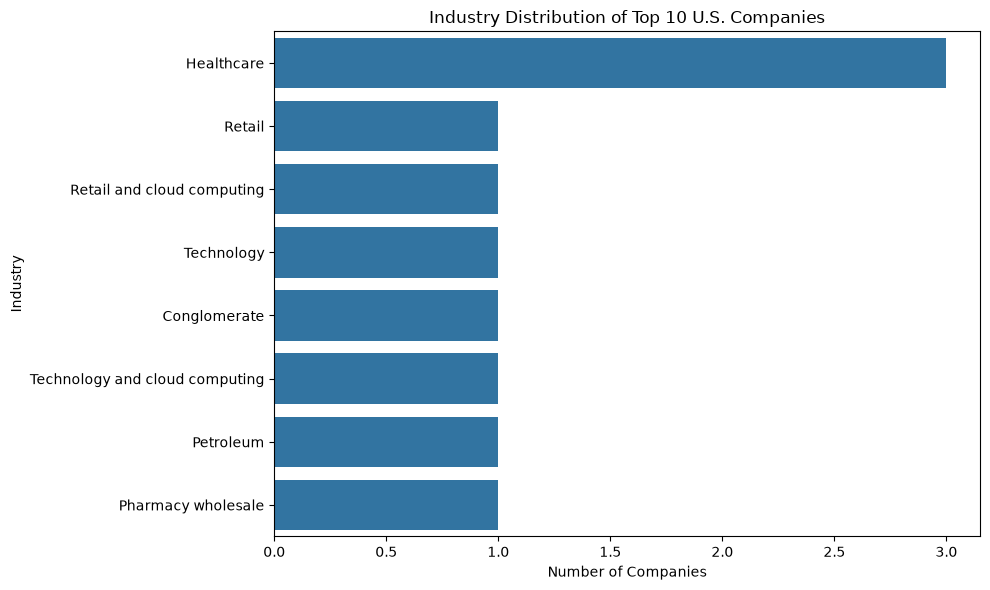

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=industry_counts.values,
    y=industry_counts.index
)

plt.title("Industry Distribution of Top 10 U.S. Companies")
plt.xlabel("Number of Companies")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

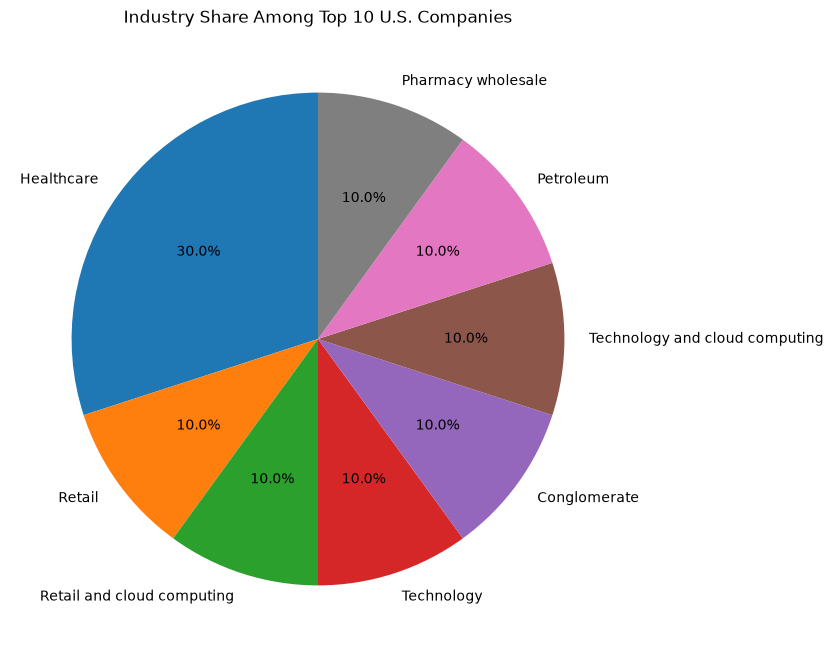

In [42]:
plt.figure(figsize=(8, 8))

industry_counts.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Industry Share Among Top 10 U.S. Companies")
plt.ylabel("")

plt.show()

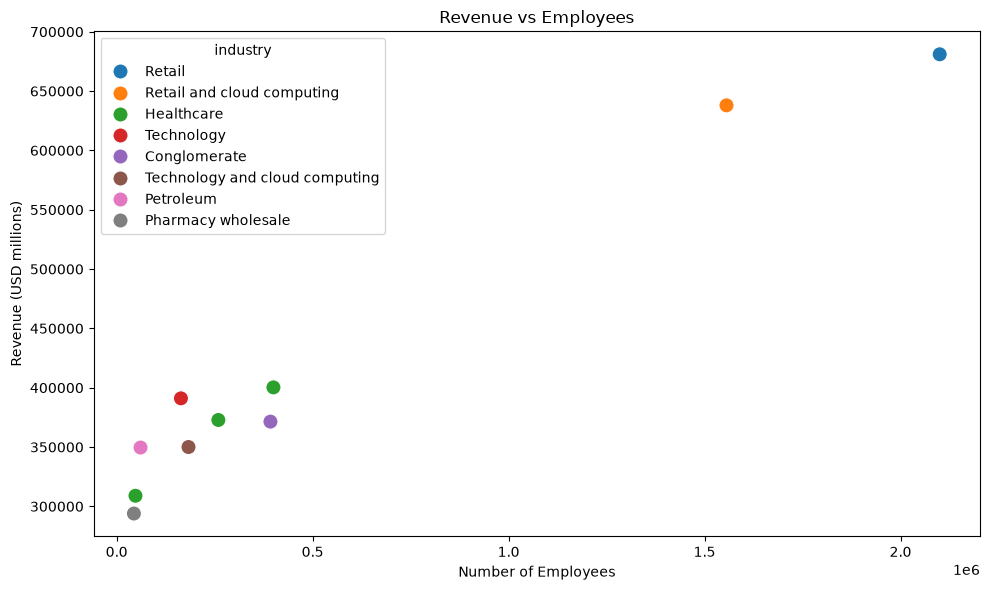

In [43]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=top10,
    x="employees",
    y="revenue_usd_millions",
    hue="industry",
    s=120
)

plt.title("Revenue vs Employees")
plt.xlabel("Number of Employees")
plt.ylabel("Revenue (USD millions)")

plt.tight_layout()
plt.show()

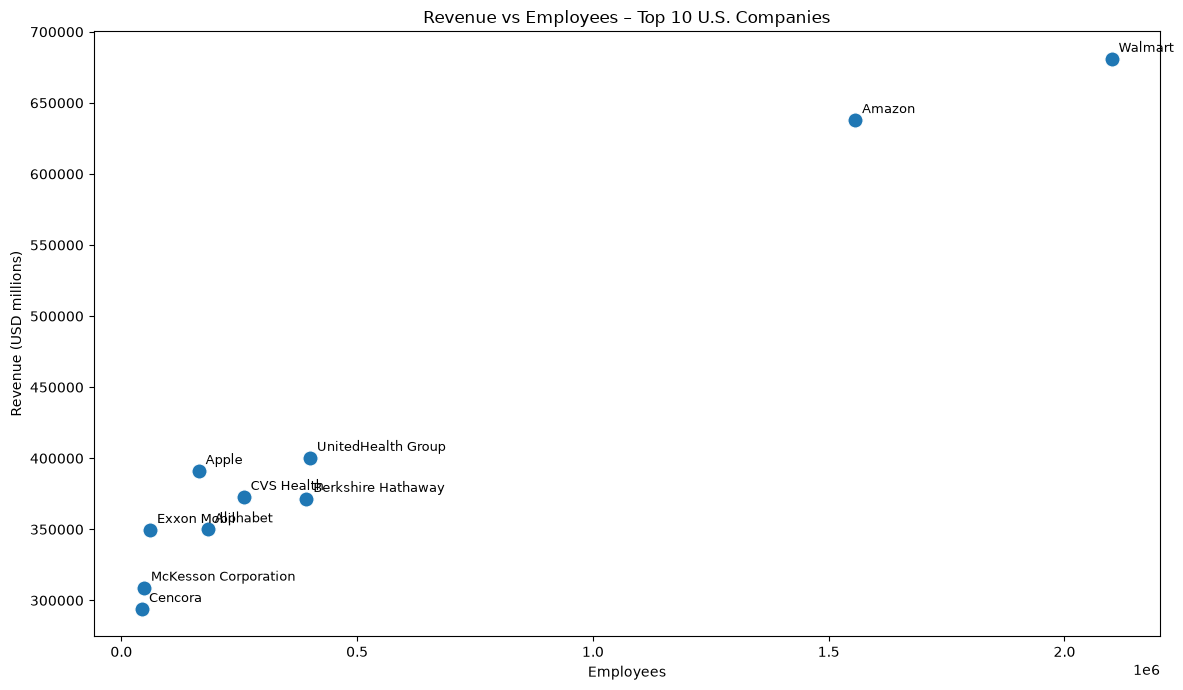

In [44]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=top10,
    x="employees",
    y="revenue_usd_millions",
    s=120
)

for _, row in top10.iterrows():
    plt.annotate(
        row["name"],
        (row["employees"], row["revenue_usd_millions"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Revenue vs Employees – Top 10 U.S. Companies")
plt.xlabel("Employees")
plt.ylabel("Revenue (USD millions)")

plt.tight_layout()
plt.show()

In [45]:
top10["revenue_per_employee"] = (
    top10["revenue_usd_millions"] * 1_000_000
) / top10["employees"]

top10[[
    "name",
    "revenue_per_employee"
]]

,name,revenue_per_employee
0,Walmart,3.242786e+05
1,Amazon,4.099994e+05
2,UnitedHealth Group,1.000695e+06
3,Apple,2.384360e+06
4,CVS Health,1.436644e+06
5,Berkshire Hathaway,9.465673e+05
6,Alphabet,1.909297e+06
7,Exxon Mobil,5.740476e+06
8,McKesson Corporation,6.436479e+06
9,Cencora,6.680886e+06


In [46]:
revenue_efficiency = top10.sort_values(
    "revenue_per_employee",
    ascending=False
)

revenue_efficiency[[
    "name",
    "revenue_per_employee"
]]

,name,revenue_per_employee
9,Cencora,6.680886e+06
8,McKesson Corporation,6.436479e+06
7,Exxon Mobil,5.740476e+06
3,Apple,2.384360e+06
6,Alphabet,1.909297e+06
4,CVS Health,1.436644e+06
2,UnitedHealth Group,1.000695e+06
5,Berkshire Hathaway,9.465673e+05
1,Amazon,4.099994e+05
0,Walmart,3.242786e+05


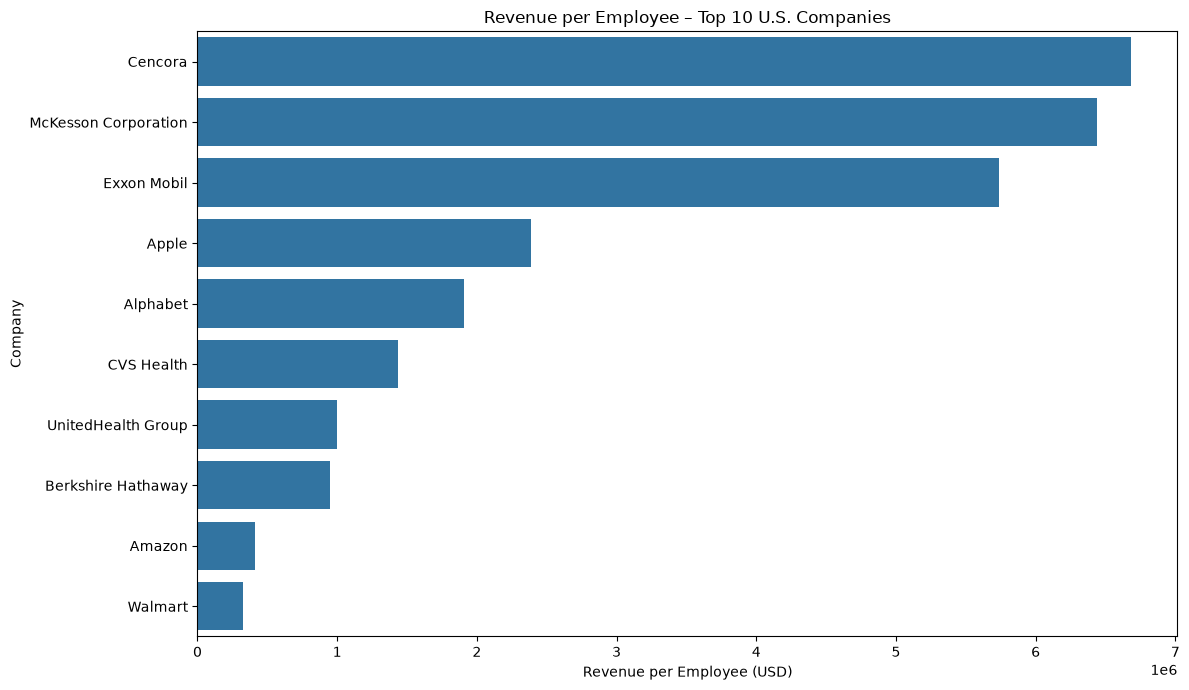

In [47]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=revenue_efficiency,
    x="revenue_per_employee",
    y="name"
)

plt.title("Revenue per Employee – Top 10 U.S. Companies")
plt.xlabel("Revenue per Employee (USD)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

In [48]:
correlation = top10[
    ["revenue_usd_millions", "employees"]
].corr()

print(correlation)

                      revenue_usd_millions  employees
revenue_usd_millions              1.000000   0.981854
employees                         0.981854   1.000000


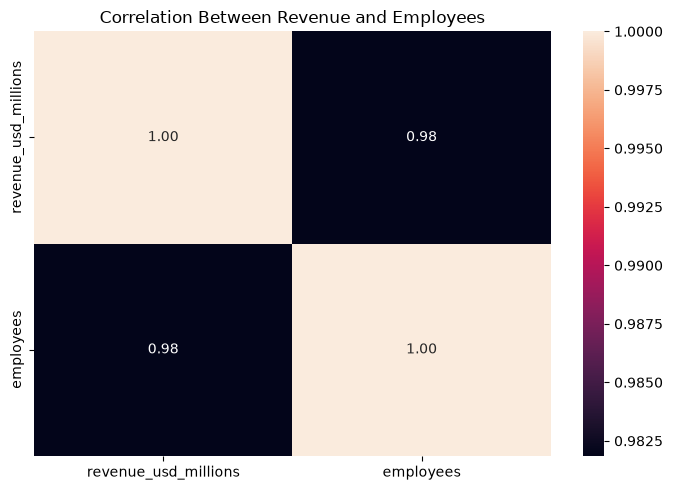

In [49]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Revenue and Employees")

plt.tight_layout()
plt.show()

In [50]:
top10.to_csv(
    "top_10_us_companies_revenue.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [51]:
top10

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters,revenue_per_employee
0,1,Walmart,Retail,680985,5.1,2100000,"Bentonville, Arkansas",3.242786e+05
1,2,Amazon,Retail and cloud computing,637959,11.0,1556000,"Seattle, Washington",4.099994e+05
2,3,UnitedHealth Group,Healthcare,400278,7.7,400000,"Minnetonka, Minnesota",1.000695e+06
3,4,Apple,Technology,391035,2.0,164000,"Cupertino, California",2.384360e+06
4,5,CVS Health,Healthcare,372809,4.2,259500,"Woonsocket, Rhode Island",1.436644e+06
5,6,Berkshire Hathaway,Conglomerate,371433,1.9,392400,"Omaha, Nebraska",9.465673e+05
6,7,Alphabet,Technology and cloud computing,350018,13.9,183323,"Mountain View, California",1.909297e+06
7,8,Exxon Mobil,Petroleum,349595,1.5,60900,"Spring, Texas",5.740476e+06
8,9,McKesson Corporation,Healthcare,308951,11.7,48000,"Irving, Texas",6.436479e+06
9,10,Cencora,Pharmacy wholesale,293959,12.1,44000,"Conshohocken, Pennsylvania",6.680886e+06


In [52]:
summary = top10[[
    "rank",
    "name",
    "industry",
    "revenue_usd_millions",
    "revenue_growth",
    "employees",
    "revenue_per_employee"
]].copy()

summary

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,revenue_per_employee
0,1,Walmart,Retail,680985,5.1,2100000,3.242786e+05
1,2,Amazon,Retail and cloud computing,637959,11.0,1556000,4.099994e+05
2,3,UnitedHealth Group,Healthcare,400278,7.7,400000,1.000695e+06
3,4,Apple,Technology,391035,2.0,164000,2.384360e+06
4,5,CVS Health,Healthcare,372809,4.2,259500,1.436644e+06
5,6,Berkshire Hathaway,Conglomerate,371433,1.9,392400,9.465673e+05
6,7,Alphabet,Technology and cloud computing,350018,13.9,183323,1.909297e+06
7,8,Exxon Mobil,Petroleum,349595,1.5,60900,5.740476e+06
8,9,McKesson Corporation,Healthcare,308951,11.7,48000,6.436479e+06
9,10,Cencora,Pharmacy wholesale,293959,12.1,44000,6.680886e+06


# Conclusion

The project successfully scraped data on the largest U.S. companies by revenue from Wikipedia using Python, Requests, and BeautifulSoup.

The scraped data was converted into a Pandas DataFrame and cleaned for analysis. The Top 10 companies were then analyzed based on revenue, revenue growth, industry, employee count, and revenue per employee.

The visualizations show differences in revenue size, growth rates, workforce distribution, industry representation, and the relationship between revenue and employees.

The analysis demonstrates how web scraping and exploratory data analysis can be used to extract meaningful business insights from publicly available data.

The project also highlights that companies with high revenue do not necessarily have the same workforce size or revenue efficiency, demonstrating the importance of examining multiple business metrics rather than relying on revenue alone.

In [53]:
profit_data = {
    "Walmart": 19436,
    "Amazon": 59248,
    "UnitedHealth Group": 14405,
    "Apple": 93736,
    "CVS Health": 4614,
    "Berkshire Hathaway": 88995,
    "Alphabet": 100118,
    "Exxon Mobil": 33680,
    "McKesson Corporation": 3002,
    "Cencora": 1509.1
}

top10["profit_usd_millions"] = top10["name"].map(profit_data)

top10[["name", "revenue_usd_millions", "profit_usd_millions"]]

,name,revenue_usd_millions,profit_usd_millions
0,Walmart,680985,19436.0
1,Amazon,637959,59248.0
2,UnitedHealth Group,400278,14405.0
3,Apple,391035,93736.0
4,CVS Health,372809,4614.0
5,Berkshire Hathaway,371433,88995.0
6,Alphabet,350018,100118.0
7,Exxon Mobil,349595,33680.0
8,McKesson Corporation,308951,3002.0
9,Cencora,293959,1509.1


In [54]:
top10.info()

<class 'pandas.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   rank                  10 non-null     str    
 1   name                  10 non-null     str    
 2   industry              10 non-null     str    
 3   revenue_usd_millions  10 non-null     int64  
 4   revenue_growth        10 non-null     float64
 5   employees             10 non-null     int64  
 6   headquarters          10 non-null     str    
 7   revenue_per_employee  10 non-null     float64
 8   profit_usd_millions   10 non-null     float64
dtypes: float64(3), int64(2), str(4)
memory usage: 852.0 bytes


In [55]:
top10[[
    "rank",
    "name",
    "industry",
    "revenue_usd_millions",
    "profit_usd_millions"
]]

,rank,name,industry,revenue_usd_millions,profit_usd_millions
0,1,Walmart,Retail,680985,19436.0
1,2,Amazon,Retail and cloud computing,637959,59248.0
2,3,UnitedHealth Group,Healthcare,400278,14405.0
3,4,Apple,Technology,391035,93736.0
4,5,CVS Health,Healthcare,372809,4614.0
5,6,Berkshire Hathaway,Conglomerate,371433,88995.0
6,7,Alphabet,Technology and cloud computing,350018,100118.0
7,8,Exxon Mobil,Petroleum,349595,33680.0
8,9,McKesson Corporation,Healthcare,308951,3002.0
9,10,Cencora,Pharmacy wholesale,293959,1509.1


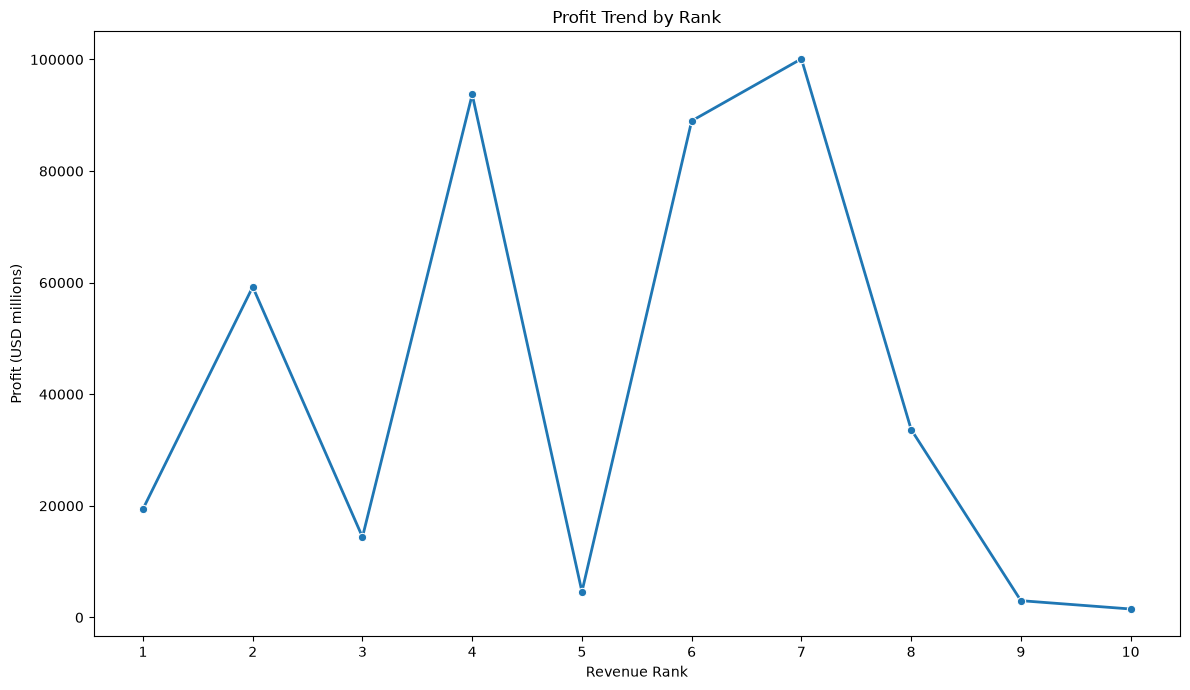

In [56]:
plt.figure(figsize=(12, 7))

sns.lineplot(
    data=top10,
    x="rank",
    y="profit_usd_millions",
    marker="o",
    linewidth=2
)

plt.title("Profit Trend by Rank")
plt.xlabel("Revenue Rank")
plt.ylabel("Profit (USD millions)")
plt.xticks(top10["rank"])

plt.tight_layout()
plt.show()

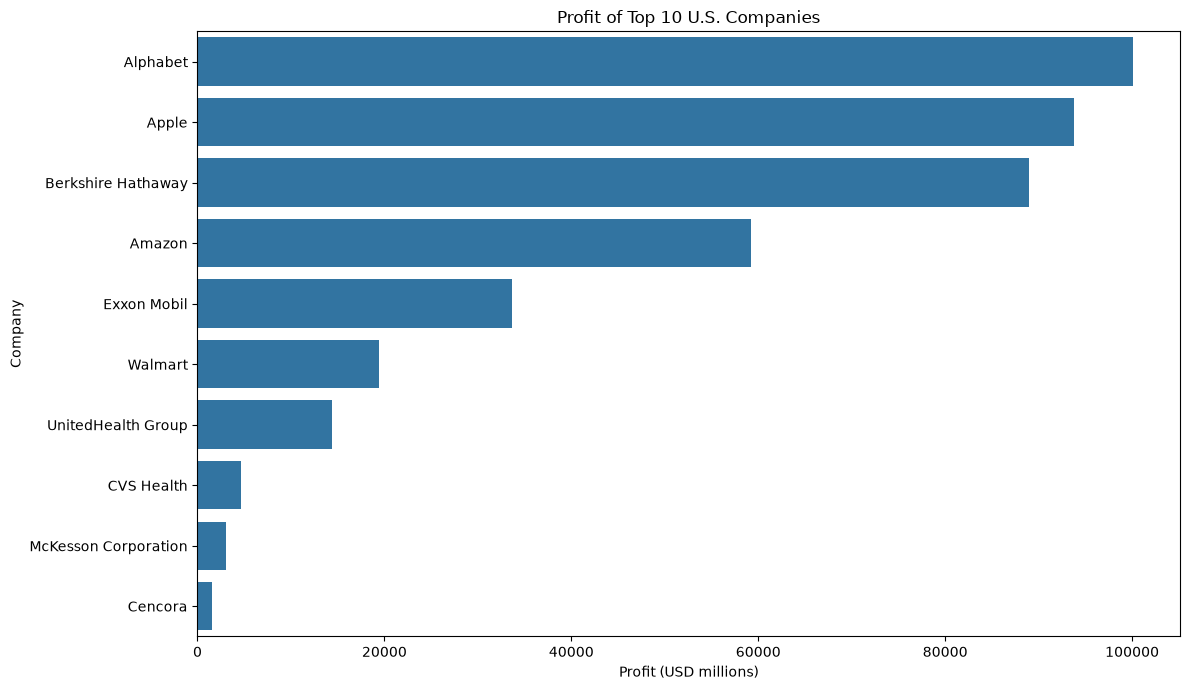

In [57]:
profit_sorted = top10.sort_values(
    "profit_usd_millions",
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=profit_sorted,
    x="profit_usd_millions",
    y="name"
)

plt.title("Profit of Top 10 U.S. Companies")
plt.xlabel("Profit (USD millions)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

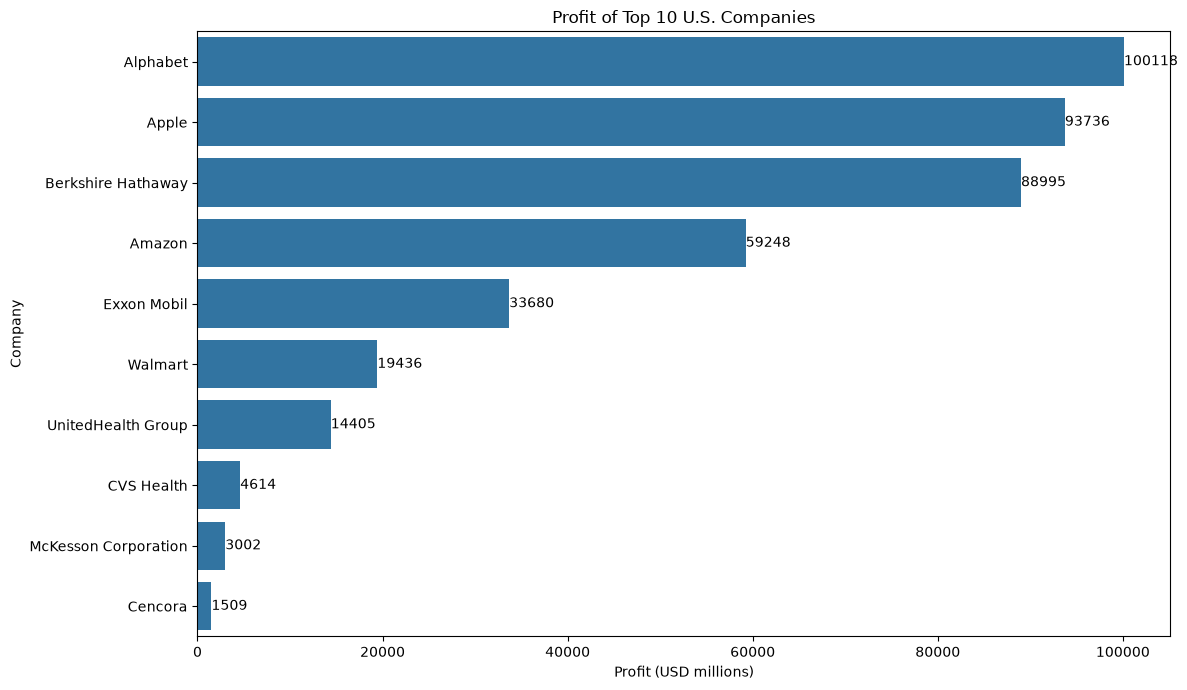

In [58]:
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=profit_sorted,
    x="profit_usd_millions",
    y="name"
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f")

plt.title("Profit of Top 10 U.S. Companies")
plt.xlabel("Profit (USD millions)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

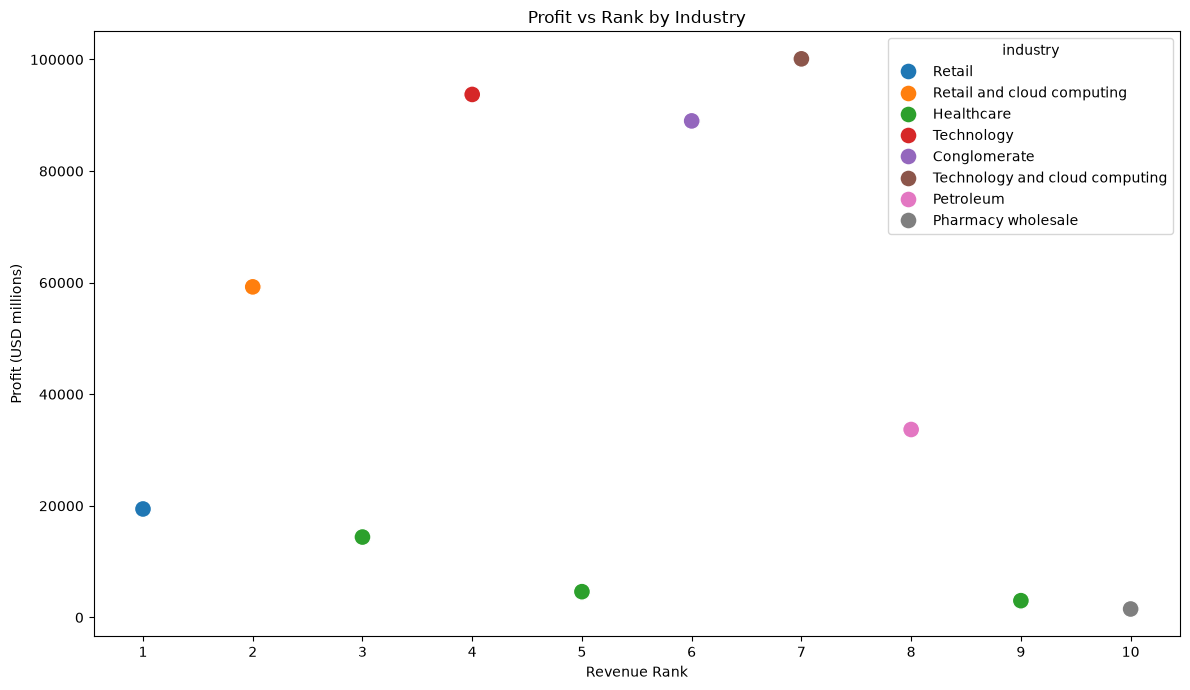

In [59]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=top10,
    x="rank",
    y="profit_usd_millions",
    hue="industry",
    s=150
)

plt.title("Profit vs Rank by Industry")
plt.xlabel("Revenue Rank")
plt.ylabel("Profit (USD millions)")

plt.tight_layout()
plt.show()

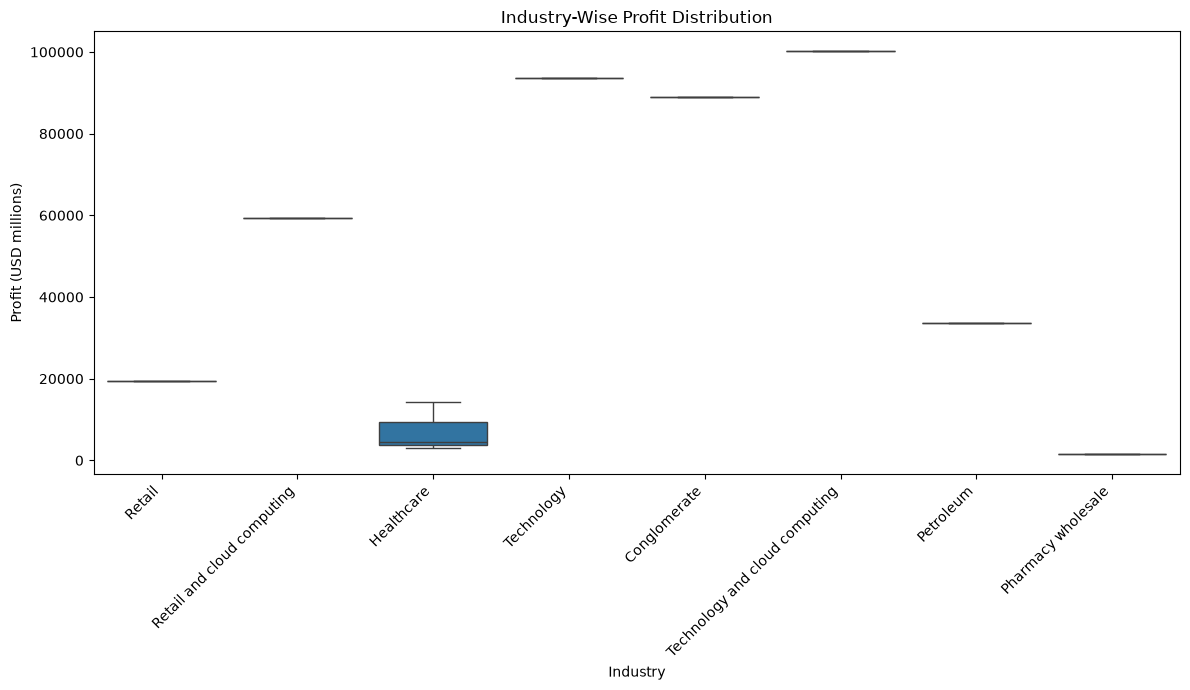

In [60]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=top10,
    x="industry",
    y="profit_usd_millions"
)

plt.title("Industry-Wise Profit Distribution")
plt.xlabel("Industry")
plt.ylabel("Profit (USD millions)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [61]:
total_profit = top10["profit_usd_millions"].sum()

print(
    f"Total profit of the Top 10 companies: "
    f"${total_profit:,.1f} million"
)

Total profit of the Top 10 companies: $418,743.1 million


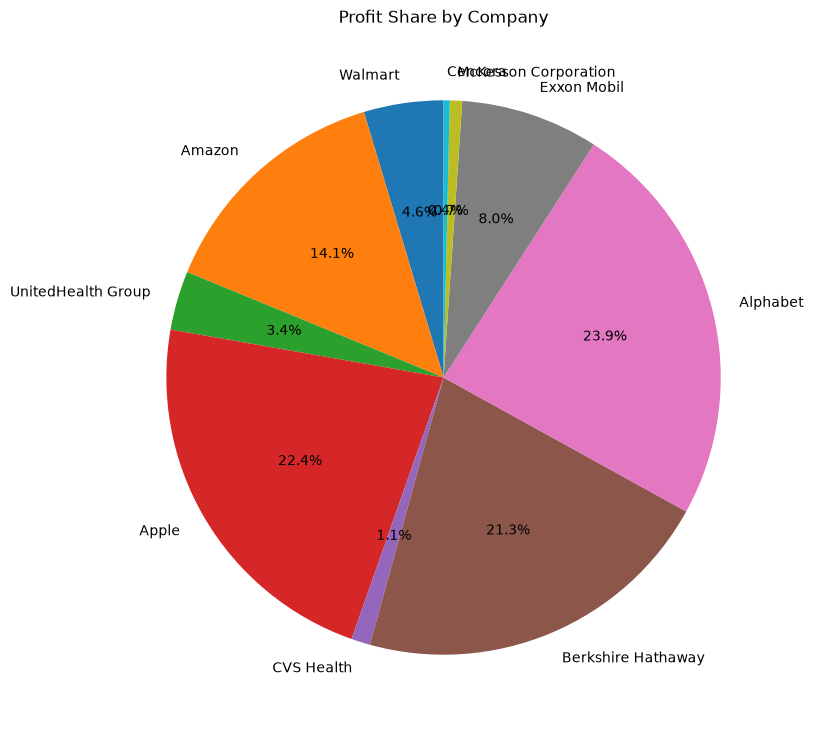

In [62]:
plt.figure(figsize=(9, 9))

plt.pie(
    top10["profit_usd_millions"],
    labels=top10["name"],
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Profit Share by Company")

plt.show()

In [63]:
top_profitable = top10.sort_values(
    "profit_usd_millions",
    ascending=False
).reset_index(drop=True)

top_profitable[[
    "name",
    "industry",
    "profit_usd_millions"
]]

,name,industry,profit_usd_millions
0,Alphabet,Technology and cloud computing,100118.0
1,Apple,Technology,93736.0
2,Berkshire Hathaway,Conglomerate,88995.0
3,Amazon,Retail and cloud computing,59248.0
4,Exxon Mobil,Petroleum,33680.0
5,Walmart,Retail,19436.0
6,UnitedHealth Group,Healthcare,14405.0
7,CVS Health,Healthcare,4614.0
8,McKesson Corporation,Healthcare,3002.0
9,Cencora,Pharmacy wholesale,1509.1


In [64]:
top_profitable.head(5)

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters,revenue_per_employee,profit_usd_millions
0,7,Alphabet,Technology and cloud computing,350018,13.9,183323,"Mountain View, California",1.909297e+06,100118.0
1,4,Apple,Technology,391035,2.0,164000,"Cupertino, California",2.384360e+06,93736.0
2,6,Berkshire Hathaway,Conglomerate,371433,1.9,392400,"Omaha, Nebraska",9.465673e+05,88995.0
3,2,Amazon,Retail and cloud computing,637959,11.0,1556000,"Seattle, Washington",4.099994e+05,59248.0
4,8,Exxon Mobil,Petroleum,349595,1.5,60900,"Spring, Texas",5.740476e+06,33680.0


In [65]:
top10["profit_margin"] = (
    top10["profit_usd_millions"]
    / top10["revenue_usd_millions"]
) * 100

top10[[
    "name",
    "revenue_usd_millions",
    "profit_usd_millions",
    "profit_margin"
]]

,name,revenue_usd_millions,profit_usd_millions,profit_margin
0,Walmart,680985,19436.0,2.854101
1,Amazon,637959,59248.0,9.287117
2,UnitedHealth Group,400278,14405.0,3.598749
3,Apple,391035,93736.0,23.971256
4,CVS Health,372809,4614.0,1.237631
5,Berkshire Hathaway,371433,88995.0,23.959907
6,Alphabet,350018,100118.0,28.603672
7,Exxon Mobil,349595,33680.0,9.634005
8,McKesson Corporation,308951,3002.0,0.971675
9,Cencora,293959,1509.1,0.513371


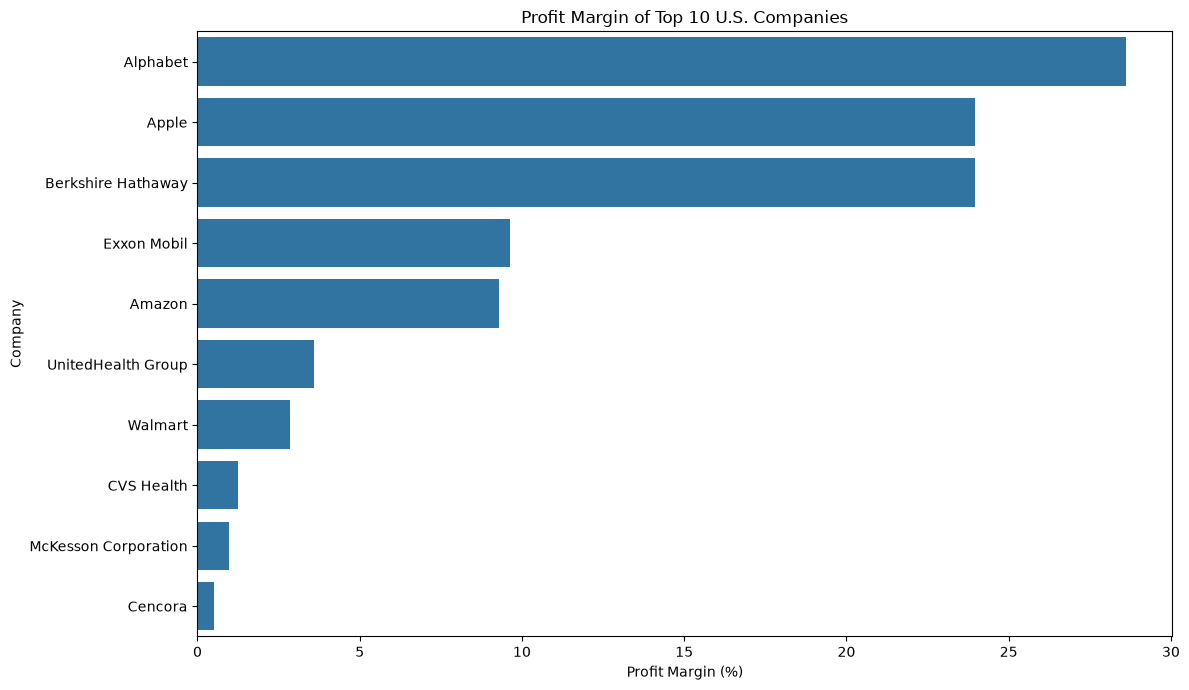

In [66]:
margin_sorted = top10.sort_values(
    "profit_margin",
    ascending=False
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=margin_sorted,
    x="profit_margin",
    y="name"
)

plt.title("Profit Margin of Top 10 U.S. Companies")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Company")

plt.tight_layout()
plt.show()

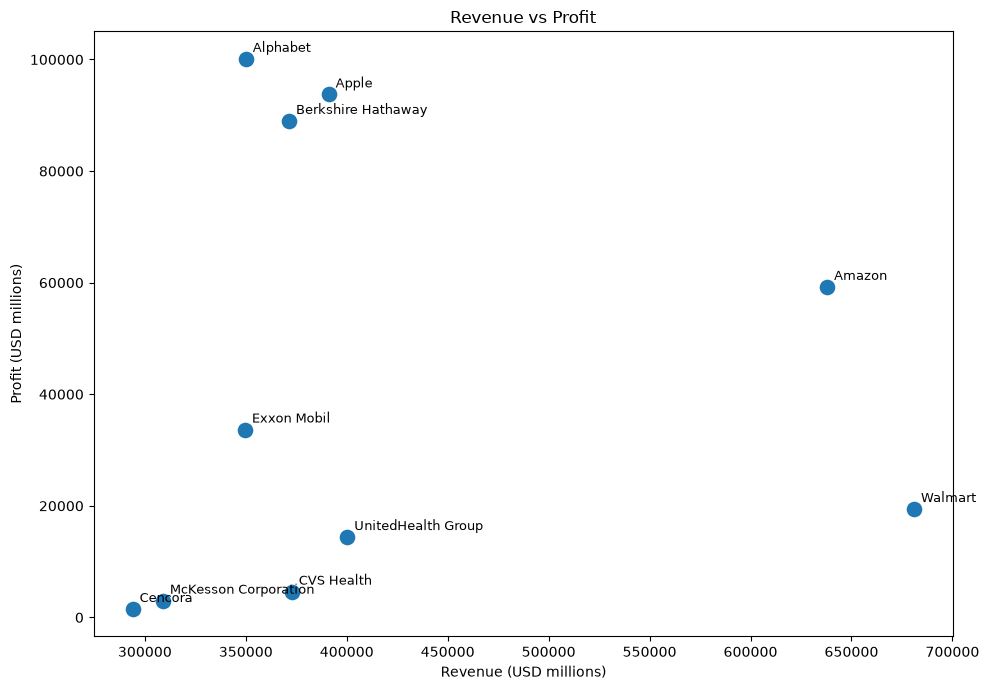

In [67]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=top10,
    x="revenue_usd_millions",
    y="profit_usd_millions",
    s=150
)

for _, row in top10.iterrows():
    plt.annotate(
        row["name"],
        (
            row["revenue_usd_millions"],
            row["profit_usd_millions"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.title("Revenue vs Profit")
plt.xlabel("Revenue (USD millions)")
plt.ylabel("Profit (USD millions)")

plt.tight_layout()
plt.show()

In [68]:
revenue_profit_correlation = top10[
    ["revenue_usd_millions", "profit_usd_millions"]
].corr()

print(revenue_profit_correlation)

                      revenue_usd_millions  profit_usd_millions
revenue_usd_millions              1.000000             0.048868
profit_usd_millions               0.048868             1.000000


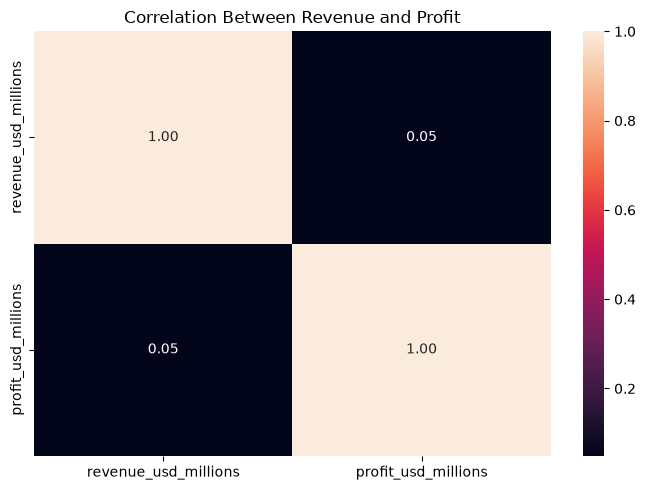

In [69]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    revenue_profit_correlation,
    annot=True,
    fmt=".2f"
)

plt.title("Correlation Between Revenue and Profit")

plt.tight_layout()
plt.show()

# Key Problems Identified

## 1. Profit Concentration

Profit is concentrated among a smaller number of companies within the Top 10 revenue-ranked companies.

## 2. Revenue Does Not Equal Profit

A high revenue ranking does not necessarily result in an equally high profit level.

## 3. Sectoral Differences

Profitability varies across industries because companies have different cost structures and operating models.

## 4. Uneven Efficiency

Companies with similar revenue levels can generate significantly different profits, indicating differences in operating efficiency.

## 5. Limited Scope

The analysis focuses only on the Top 10 companies by revenue and therefore does not represent the entire U.S. corporate sector.

# Recommendations

## 1. Evaluate Revenue and Profit Together

Company performance should be evaluated using both revenue and profitability rather than revenue alone.

## 2. Improve Operational Efficiency

Companies with lower profit margins can examine their operating costs and business processes to identify opportunities for improving efficiency.

## 3. Use Industry-Specific Benchmarks

Because profitability differs across industries, companies should compare their performance with relevant industry benchmarks.

## 4. Expand the Dataset

Future analysis should include the Top 50 or Top 100 companies to provide a broader understanding of U.S. corporate performance.

In [70]:
top10.to_csv(
    "top_10_us_companies_revenue_profit.csv",
    index=False
)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [71]:
top10

,rank,name,industry,revenue_usd_millions,revenue_growth,employees,headquarters,revenue_per_employee,profit_usd_millions,profit_margin
0,1,Walmart,Retail,680985,5.1,2100000,"Bentonville, Arkansas",3.242786e+05,19436.0,2.854101
1,2,Amazon,Retail and cloud computing,637959,11.0,1556000,"Seattle, Washington",4.099994e+05,59248.0,9.287117
2,3,UnitedHealth Group,Healthcare,400278,7.7,400000,"Minnetonka, Minnesota",1.000695e+06,14405.0,3.598749
3,4,Apple,Technology,391035,2.0,164000,"Cupertino, California",2.384360e+06,93736.0,23.971256
4,5,CVS Health,Healthcare,372809,4.2,259500,"Woonsocket, Rhode Island",1.436644e+06,4614.0,1.237631
5,6,Berkshire Hathaway,Conglomerate,371433,1.9,392400,"Omaha, Nebraska",9.465673e+05,88995.0,23.959907
6,7,Alphabet,Technology and cloud computing,350018,13.9,183323,"Mountain View, California",1.909297e+06,100118.0,28.603672
7,8,Exxon Mobil,Petroleum,349595,1.5,60900,"Spring, Texas",5.740476e+06,33680.0,9.634005
8,9,McKesson Corporation,Healthcare,308951,11.7,48000,"Irving, Texas",6.436479e+06,3002.0,0.971675
9,10,Cencora,Pharmacy wholesale,293959,12.1,44000,"Conshohocken, Pennsylvania",6.680886e+06,1509.1,0.513371


In [72]:
final_summary = top10[[
    "rank",
    "name",
    "industry",
    "revenue_usd_millions",
    "revenue_growth",
    "profit_usd_millions",
    "profit_margin",
    "employees"
]]

final_summary

,rank,name,industry,revenue_usd_millions,revenue_growth,profit_usd_millions,profit_margin,employees
0,1,Walmart,Retail,680985,5.1,19436.0,2.854101,2100000
1,2,Amazon,Retail and cloud computing,637959,11.0,59248.0,9.287117,1556000
2,3,UnitedHealth Group,Healthcare,400278,7.7,14405.0,3.598749,400000
3,4,Apple,Technology,391035,2.0,93736.0,23.971256,164000
4,5,CVS Health,Healthcare,372809,4.2,4614.0,1.237631,259500
5,6,Berkshire Hathaway,Conglomerate,371433,1.9,88995.0,23.959907,392400
6,7,Alphabet,Technology and cloud computing,350018,13.9,100118.0,28.603672,183323
7,8,Exxon Mobil,Petroleum,349595,1.5,33680.0,9.634005,60900
8,9,McKesson Corporation,Healthcare,308951,11.7,3002.0,0.971675,48000
9,10,Cencora,Pharmacy wholesale,293959,12.1,1509.1,0.513371,44000


# Conclusion

The project successfully demonstrated the process of extracting, cleaning, analyzing, and visualizing data on the Top 10 U.S. companies by revenue.

Data was scraped from Wikipedia using Requests and BeautifulSoup and organized using Pandas. The analysis examined revenue, revenue growth, employee count, industry distribution, profit, profit margin, and revenue efficiency.

The visualizations provided insights into differences in company scale, workforce size, industry representation, profitability, and the relationship between revenue and profit.

The analysis demonstrates that revenue alone does not provide a complete picture of corporate performance. Profitability and profit margins provide additional information about how effectively companies convert revenue into earnings.

The project can be extended in the future by analyzing the Top 50 or Top 100 companies and conducting more comprehensive statistical and industry-level analysis.